# Meta-Learning Lintas Stasiun untuk Penggabungan Dinamis Prakiraan Curah Hujan Bulanan

Notebook ini menjalankan seluruh eksperimen naskah dari data mentah sampai tabel dan gambar:

1. **Data curah hujan.** Curah hujan harian SILO 15 stasiun (1926–2025) diubah menjadi total bulanan dengan masker pengamatan.
2. **Indeks iklim.** Niño3.4 (ERSST v5), DMI (HadISST), dan SOI (CRU).
3. **Model dasar.** SARIMA, SVR, XGBoost, LSTM, GRU, dan empat hibrida VMD/wavelet dilatih ulang tiap 5 tahun sejak 1961. Dua klimatologi bergulir ditambahkan sehingga pool berisi 11 anggota.
4. **Gate meta-learner.** Gate lokal per stasiun (L-G3, L-G4), gate global lintas stasiun (GG3, GG4), dan gate transfer tanpa stasiun uji (GG4-T).
5. **Evaluasi.** NSE, RMSE, MAE, uji Diebold–Mariano per stasiun dengan koreksi Holm, dan uji DM panel lintas stasiun dengan galat kuadrat dan galat absolut.
6. **Tabel 1–6 dan Gambar 1–4 naskah**, laporan eksperimen lengkap, dan pemeriksaan angka-angka yang dikutip di naskah.

**Dua cara menjalankan**

| Mode | Pengaturan | Waktu (CPU 16 inti) |
|---|---|---|
| Reproduksi (bawaan) | `LATIH_ULANG_MODEL_DASAR = False`, `LATIH_ULANG_GATE = False` | ± 3 menit |
| Pipeline penuh | kedua saklar `True` | ± 25 menit dengan 15 proses paralel; ± 4–5 jam dengan 1 proses |

Mode reproduksi memakai keluaran model dasar dan gate yang tersimpan di `hasil/`, lalu menyusun ulang dataset meta, evaluasi, tabel, dan gambar. Mode penuh melatih ulang semua model. Pada perangkat keras atau versi pustaka yang berbeda, pelatihan ulang dapat menghasilkan selisih numerik kecil.

## 0. Pengaturan

In [1]:
import os
LATIH_ULANG_MODEL_DASAR = False   # True: latih ulang 9 model dasar x 15 stasiun (pelatihan ulang bergulir 1961-2021)
LATIH_ULANG_GATE = False          # True: latih ulang gate lokal, global, dan transfer (3 seed per gate)
SIAPKAN_ULANG_DATA = True         # True: agregasi bulanan dan indeks iklim dihitung ulang dari data mentah
WORKERS = max(1, (os.cpu_count() or 2) - 1)   # jumlah proses paralel untuk pelatihan

In [2]:
import sys, json, glob, shutil, subprocess, time, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC, HASIL, OLAHAN = ROOT / "src", ROOT / "hasil", ROOT / "data" / "olahan"
sys.path.insert(0, str(SRC))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

def jalankan(*args, env_extra=None):
    # Menjalankan skrip di src/ sebagai proses terpisah dan menampilkan keluarannya baris demi baris.
    env = {**os.environ, "WORKERS": str(WORKERS), "PYTHONIOENCODING": "utf-8", **(env_extra or {})}
    p = subprocess.Popen([sys.executable, str(SRC / args[0]), *args[1:]], cwd=ROOT, env=env,
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
    abaikan = ("WARNING", "I0000", "W0000", "oneDNN", "cpu_feature_guard", "To enable the following", "absl::")
    for line in p.stdout:
        if not any(a in line for a in abaikan): print(line, end="")
    if p.wait() != 0: raise RuntimeError(f"{args[0]} gagal (kode {p.returncode})")

def baca(path): return open(path, "rb").read() if Path(path).exists() else None

def _selisih(a, b):   # selisih numerik maksimum antara dua struktur JSON (inf jika strukturnya berbeda)
    if isinstance(a, dict): return max([_selisih(a[k], b[k]) for k in a], default=0.0) if isinstance(b, dict) and a.keys() == b.keys() else np.inf
    if isinstance(a, list): return max([_selisih(u, v) for u, v in zip(a, b)], default=0.0) if isinstance(b, list) and len(a) == len(b) else np.inf
    if isinstance(a, (int, float)) and isinstance(b, (int, float)): return 0.0 if (a != a and b != b) else abs(a - b)
    return 0.0 if a == b else np.inf

def bandingkan(path, lama):
    # Membandingkan berkas yang baru dibuat dengan versi di repositori (isi biner dulu, lalu nilai numerik).
    if lama is None: return "baru dibuat"
    baru = open(path, "rb").read(); norm = lambda x: x.replace(b"\r\n", b"\n")
    if norm(baru) == norm(lama): return "identik dengan versi di repositori"
    import io
    try:
        if str(path).endswith(".json"): d = _selisih(json.loads(lama), json.loads(baru))
        else:
            A, B = pd.read_csv(io.BytesIO(lama)), pd.read_csv(io.BytesIO(baru)); num = A.select_dtypes("number").columns
            d = float(np.nanmax(np.abs(A[num].values - B[num].values))) if A.drop(columns=num).equals(B.drop(columns=num)) and list(A.columns) == list(B.columns) else np.inf
    except Exception: d = np.inf
    return f"identik secara numerik (selisih maks {d:.1e})" if d < 1e-9 else f"BERBEDA dari versi di repositori (selisih maks {d:.3g})"

import sklearn, scipy, statsmodels, xgboost, matplotlib
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| statsmodels", statsmodels.__version__, "| xgboost", xgboost.__version__)
print("Akar repositori:", ROOT.name)

Python 3.13.7 | numpy 2.5.4 | pandas 3.1.0 | scipy 1.18.1 | scikit-learn 1.9.1 | statsmodels 0.15.0 | xgboost 3.4.1
Akar repositori: cross-station-meta-learning-monthly-rainfall


## 1. Data curah hujan SILO

Sumber: SILO Patched Point Dataset (Queensland Government) untuk 15 stasiun Bureau of Meteorology, Januari 1926 – Desember 2025 (`data/mentah/SILO_15_stations_rainfall_1926_2025.zip`).

SILO mengisi hari tanpa pengamatan dengan interpolasi. Karena itu, sebuah bulan dipakai sebagai **target latih dan evaluasi** hanya jika sedikitnya 90% harinya berkode pengamatan langsung (kode 0, 13, 15, 23). Bulan hasil interpolasi tetap boleh dipakai sebagai **masukan** model.

In [3]:
from siapkan_data import siapkan_curah_hujan
sebelum = {f: baca(OLAHAN / f) for f in ["monthly_15.json", "cakupan_observasi.csv"]}
if SIAPKAN_ULANG_DATA:
    cov = siapkan_curah_hujan()
    for f, lama in sebelum.items(): print(f, bandingkan(OLAHAN / f, lama))
cov = pd.read_csv(OLAHAN / "cakupan_observasi.csv", dtype={"id": str})
display(cov.rename(columns={"cov_1926_1960": "teramati 1926-60", "cov_1961_2009": "1961-2009", "cov_2010_2014": "2010-14",
                            "cov_2015_2020": "2015-20", "cov_2021_2025": "2021-25", "mean_mm": "hujan rata2 (mm/bln)"}))

15 stasiun, 1200 bulan, 547,875 baris harian
monthly_15.json identik dengan versi di repositori
cakupan_observasi.csv identik dengan versi di repositori


,stasiun,id,iklim,lat,lon,teramati 1926-60,1961-2009,2010-14,2015-20,2021-25,hujan rata2 (mm/bln)
0,Darwin,014015,Tropis bermusim,-12.4239,130.8925,0.571,1.000,1.000,1.000,1.000,140.3
1,Katherine,014902,Tropis bermusim,-14.4589,132.2572,0.998,0.886,0.883,1.000,0.883,82.9
2,Broome,003003,Tropis semi-kering bermusim,-17.9475,122.2352,0.583,1.000,1.000,0.986,1.000,52.2
3,Cairns,031011,Tropis basah,-16.8736,145.7458,0.524,1.000,1.000,0.958,0.967,173.6
4,Innisfail,032025,Tropis basah,-17.5249,146.0345,1.000,0.719,1.000,0.917,0.000,298.0
5,Tully,032042,Tropis basah,-17.9364,145.9253,0.995,1.000,1.000,1.000,1.000,341.8
6,Brisbane,040214,Subtropis pesisir,-27.4778,153.0306,1.000,0.888,1.000,0.972,1.000,93.7
7,Coffs_Harbour,059040,Subtropis pesisir,-30.3107,153.1187,0.117,1.000,1.000,0.097,0.000,141.8
8,Alice_Springs,015590,Pedalaman kering,-23.7951,133.8890,0.548,1.000,1.000,0.986,0.967,22.5
9,Woomera,016001,Pedalaman kering,-31.1558,136.8054,0.317,1.000,1.000,0.986,0.950,14.7


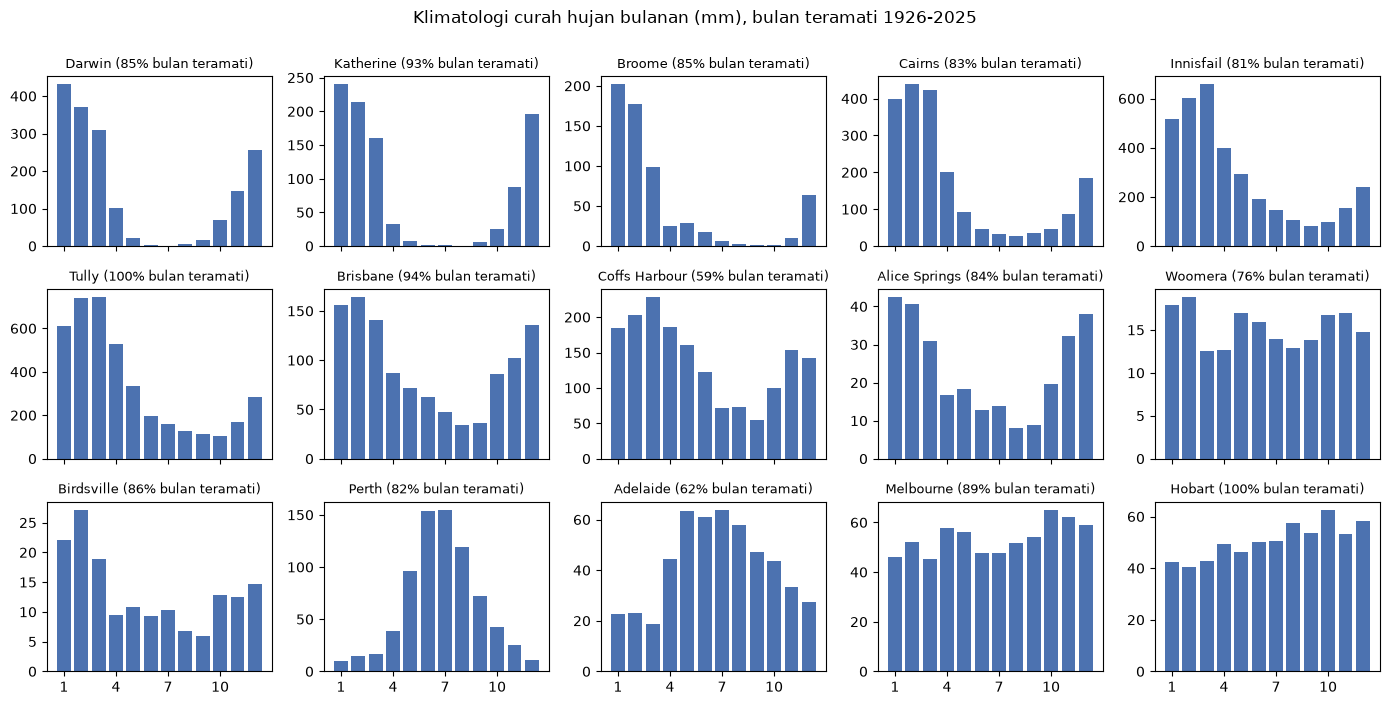

In [4]:
MON = json.load(open(OLAHAN / "monthly_15.json"))
fig, axes = plt.subplots(3, 5, figsize=(14, 7), sharex=True)
for ax, (st, s) in zip(axes.ravel(), MON["stations"].items()):
    y, ok = np.array(s["rain"]), np.array(s["ok"], bool); mon = np.arange(1200) % 12
    ax.bar(range(1, 13), [y[(mon == m) & ok].mean() for m in range(12)], color="#4c72b0")
    ax.set_title(f"{st.replace('_', ' ')} ({100 * ok.mean():.0f}% bulan teramati)", fontsize=9); ax.set_xticks([1, 4, 7, 10])
fig.suptitle("Klimatologi curah hujan bulanan (mm), bulan teramati 1926-2025", y=1.0); plt.tight_layout(); plt.show()

## 2. Indeks iklim

- **Niño3.4**: ERSST v5. Untuk 1926–1949, rata-rata kotak 5°LU–5°LS, 190°–240°BT dihitung dari berkas grid NCEI (`ersst_v5_ncei_1921_1939.zip`, `ersst_v5_ncei_1940_1960.zip`); mulai 1950 dipakai deret CPC (`ersst5_nino_cpc.ascii`). Anomali dihitung terhadap klimatologi 1926–1960.
- **DMI**: Dipole Mode Index HadISST (NOAA PSL, `dmi_had.txt`).
- **SOI**: Southern Oscillation Index Climatic Research Unit (`soi_cru.dat`).

Untuk meniru jadwal rilis data, model hanya memakai Niño3.4 dan DMI sampai bulan *o* − 2 dan SOI sampai bulan *o* − 1 (*o* = bulan target pertama).

Nino3.4 grid vs CPC, tumpang tindih 132 bulan: r = 0.99997 | selisih maks = 0.024 degC
nilai hilang: {'nino34': 0, 'dmi': 0, 'soi': 0}
indeks_iklim_1926_2025.csv identik dengan versi di repositori


,count,mean,std,min,25%,50%,75%,max
nino34,1200.0,0.26,0.87,-1.86,-0.36,0.18,0.78,3.45
dmi,1200.0,-0.15,0.35,-1.57,-0.38,-0.16,0.05,1.28
soi,1200.0,-0.07,1.06,-3.46,-0.75,-0.04,0.64,3.06


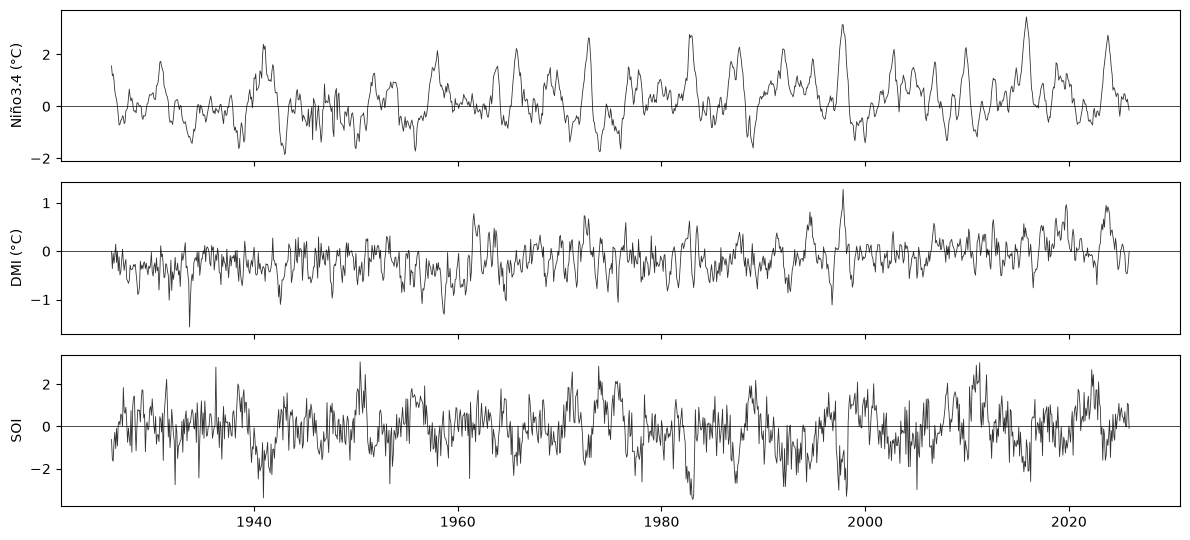

In [5]:
from indeks_iklim import hitung_indeks
lama = baca(OLAHAN / "indeks_iklim_1926_2025.csv")
if SIAPKAN_ULANG_DATA:
    hitung_indeks()
    print("indeks_iklim_1926_2025.csv", bandingkan(OLAHAN / "indeks_iklim_1926_2025.csv", lama))
IDX = pd.read_csv(OLAHAN / "indeks_iklim_1926_2025.csv", index_col=0)
display(IDX.describe().round(2).T)
fig, axes = plt.subplots(3, 1, figsize=(12, 5.5), sharex=True)
t = pd.PeriodIndex(IDX.index, freq="M").to_timestamp()
for ax, c, lab in zip(axes, ["nino34", "dmi", "soi"], ["Niño3.4 (°C)", "DMI (°C)", "SOI"]):
    ax.plot(t, IDX[c], lw=0.6, color="#333333"); ax.axhline(0, color="k", lw=0.5); ax.set_ylabel(lab)
plt.tight_layout(); plt.show()

## 3. Model dasar dengan pelatihan ulang bergulir

Setiap stasiun memiliki sembilan model dasar:

| Paradigma | Model | Masukan |
|---|---|---|
| Statistik | SARIMA(2,1,2)(1,1,1)<sub>12</sub> | deret curah hujan |
| *Machine learning* | SVR (RBF), XGBoost | 12 lag curah hujan, 6 lag tiap indeks iklim, sinus–kosinus bulan target; satu model per horizon |
| *Deep learning* | LSTM, GRU (64 unit) | urutan 12 bulan (curah hujan, indeks, bulan); keluaran 4 horizon sekaligus |
| Hibrida | XGBoost-VMD, XGBoost-WT, LSTM-VMD, LSTM-WT | lag curah hujan diganti 3 pita frekuensi dari VMD kausal atau wavelet à trous Haar |

Semua model dilatih ulang setiap 5 tahun sejak Januari 1961 (13 kali, terakhir Januari 2021) hanya dengan data sebelum titik pelatihan ulang. Di antara dua pelatihan ulang, parameter dibekukan dan prakiraan dibuat setiap bulan untuk horizon 1, 3, 6, dan 12 bulan. VMD dijalankan ulang pada setiap titik awal dengan data masa lalu saja. Dua klimatologi bergulir (ekspansif dan 30 tahun) melengkapi pool menjadi 11 anggota.

Kode: `src/base_roll.py`. Satu stasiun membutuhkan ± 15 menit dengan satu inti CPU.

In [6]:
if LATIH_ULANG_MODEL_DASAR:
    arsip = HASIL / f"arsip_{time.strftime('%Y%m%d_%H%M%S')}"; arsip.mkdir()
    for f in HASIL.glob("model_dasar_*.npz"): shutil.move(str(f), arsip / f.name)
    print("Keluaran lama dipindahkan ke", arsip.name, "| mulai melatih dengan", WORKERS, "proses paralel")
    jalankan("run_all.py", "base")
fs = sorted(HASIL.glob("model_dasar_*.npz")); print(len(fs), "berkas model dasar tersedia")
assert len(fs) == 15, "Keluaran model dasar belum lengkap; jalankan dengan LATIH_ULANG_MODEL_DASAR = True"

15 berkas model dasar tersedia


In [7]:
# Kinerja model dasar pada uji 2015-2025: NSE rata-rata lintas 13 stasiun uji, per horizon
from common import TE0, N, HORIZONS
UJI = [s for s in MON["stations"] if s not in ("Coffs_Harbour", "Melbourne")]
rows = []
for st in UJI:
    B = np.load(HASIL / f"model_dasar_{st}.npz"); names = list(B["names"]) + ["Klim-ekspansif", "Klim-30th"]
    c30 = np.where(np.isnan(B["clim30"]), B["clim"], B["clim30"])
    F = np.concatenate([B["F"], B["clim"][None], c30[None]])
    for j, h in enumerate(HORIZONS):
        T = B["orig"] + h - 1; k = (T >= TE0) & (T < N) & B["OK"][:, j]
        y = B["Y"][k, j]; den = np.sum((y - y.mean())**2)
        for i, nm in enumerate(names):
            rows.append({"stasiun": st, "h": h, "model": nm, "NSE": 1 - np.sum((y - F[i, k, j])**2) / den})
NSE_DASAR = pd.DataFrame(rows).groupby(["model", "h"])["NSE"].mean().unstack().round(3)
display(Markdown("**NSE rata-rata model dasar, uji 2015-2025 (13 stasiun)**")); display(NSE_DASAR)

**NSE rata-rata model dasar, uji 2015-2025 (13 stasiun)**

h,1,3,6,12
model,,,,
GRU,0.338,0.325,0.321,0.294
Klim-30th,0.300,0.300,0.300,0.300
Klim-ekspansif,0.320,0.320,0.320,0.320
LSTM,0.315,0.294,0.297,0.293
LSTM-VMD,0.320,0.303,0.295,0.308
LSTM-WT,0.319,0.299,0.282,0.297
SARIMA,0.319,0.321,0.320,0.319
SVR,0.275,0.256,0.235,0.244
XGBoost,0.236,0.237,0.201,0.169


## 4. Dataset meta dan gate meta-learner

Untuk setiap stasiun *s*, titik awal *o*, dan horizon *h*, gate menerima:

- riwayat galat terskala 12 bulan terakhir dari ke-11 anggota pool (dirangkum LSTM 16 unit);
- prakiraan anggota saat ini, sinus–kosinus bulan target, 6 fitur rezim ENSO/IOD, dan vektor *one-hot* horizon.

Gate menghasilkan bobot konveks melalui softmax:

$$\mathbf{w}_{s,o,h}=\mathrm{softmax}(\mathbf{V}\mathbf{z}_{s,o,h}+\mathbf{b}),\qquad \hat{y}^{G}_{s,o,h}=\sum_{m=1}^{M} w_{m,s,o,h}\,\hat{y}_{m,s,o,h}$$

| Gate | Data latih | Masukan tambahan | Jangkar NNLS |
|---|---|---|---|
| L-G3 | satu stasiun | – | tidak |
| L-G4 | satu stasiun | – | ya (per stasiun) |
| GG3 | 15 stasiun | *embedding* stasiun (dim. 4) + 6 fitur statis | tidak |
| GG4 | 15 stasiun | *embedding* stasiun + fitur statis | ya (per stasiun) |
| GG4-T | 12 stasiun (5 *fold* kelompok) | fitur statis saja | ya (gabungan stasiun latih) |

Meta-latih memakai bulan target 1962–2009, *early stopping* memakai 2010–2014, dan uji 2015–2025. Setiap gate dilatih dengan 3 seed lalu prakiraannya dirata-rata. Kode: `src/meta_global.py`.

Dataset meta (± 58 MB) tidak disimpan di repositori karena dapat disusun ulang dari keluaran model dasar dalam beberapa detik.

In [8]:
jalankan("meta_global.py", "build")
Z = np.load(HASIL / "meta_dataset.npz")
split = np.where(Z["T"] < 1008, "meta-latih 1962-2009", np.where(Z["T"] < 1068, "validasi 2010-2014", "uji 2015-2025"))
tab = pd.crosstab(pd.Series(split, name="periode"), pd.Series(np.where(Z["ok"], "teramati", "tidak teramati"), name="target"), margins=True, margins_name="total")
display(tab.loc[["meta-latih 1962-2009", "validasi 2010-2014", "uji 2015-2025", "total"]])
print("Pool (11 anggota):", ", ".join(map(str, Z["pool"])))

build Darwin 3032
build Katherine 6064


build Broome 9096
build Cairns 12128


build Innisfail 15160
build Tully 18192


build Brisbane 21224
build Coffs_Harbour 24256


build Alice_Springs 27288
build Woomera 30320


build Birdsville 33352
build Perth 36384


build Adelaide 39416
build Melbourne 42448


build Hobart 45480


target,teramati,tidak teramati,total
periode,,,
meta-latih 1962-2009,31160,2800,33960
validasi 2010-2014,3092,508,3600
uji 2015-2025,6096,1824,7920
total,40348,5132,45480


Pool (11 anggota): SARIMA, SVR, XGBoost, XGBoost-VMD, XGBoost-WT, LSTM, GRU, LSTM-VMD, LSTM-WT, Klim-ekspansif, Klim-30th


In [9]:
if LATIH_ULANG_GATE:
    arsip = HASIL / f"arsip_gate_{time.strftime('%Y%m%d_%H%M%S')}"; arsip.mkdir()
    for f in HASIL.glob("pred_*.npz"): shutil.move(str(f), arsip / f.name)
    print("Prediksi gate lama dipindahkan ke", arsip.name)
    jalankan("run_all.py", "meta")
print("Prediksi gate tersedia:", len(list(HASIL.glob("pred_local_*.npz"))), "lokal,", len(list(HASIL.glob("pred_global_*.npz"))), "global,",
      len(list(HASIL.glob("pred_transfer_*.npz"))), "transfer")

Prediksi gate tersedia: 15 lokal, 2 global, 5 transfer


## 5. Evaluasi

- **NSE** per stasiun, horizon, dan periode (2015–2025, 2015–2020, 2021–2025).
- **Uji DM** per stasiun dengan koreksi Harvey–Leybourne–Newbold, lalu koreksi Holm atas 52 kombinasi stasiun–horizon.
- **Uji DM panel**: pada setiap bulan target, selisih galat kuadrat terskala dirata-rata lintas stasiun, lalu uji DM diterapkan pada deret rata-rata tersebut. Nilai *p* dikoreksi Holm atas empat horizon.
- **Diagnosis kelayakan ensemble** pada data pra-uji 1962–2014.

Pembanding statis: rata-rata sederhana 9 model dasar (Rata2), *stacking* NNLS per stasiun–horizon (bobot dari 1962–2014), model terbaik pra-uji, dan klimatologi bergulir 30 tahun (Klim30). Kode: `src/eval_global.py`.

In [10]:
lama = baca(HASIL / "hasil_evaluasi.json")
jalankan("eval_global.py")
print("\nhasil_evaluasi.json", bandingkan(HASIL / "hasil_evaluasi.json", lama))


== NSE rata-rata lintas stasiun uji, 2015-2025
h=1 (13 stasiun) {'Klim-30th': 0.3, 'Klim-ekspansif': 0.32, 'Rata-rata': 0.339, 'NNLS': 0.33, 'Model terbaik': 0.326, 'L-G3': 0.326, 'L-G4': 0.332, 'GG3': 0.34, 'GG4': 0.336, 'GG4-transfer': 0.338}
h=3 (13 stasiun) {'Klim-30th': 0.3, 'Klim-ekspansif': 0.32, 'Rata-rata': 0.326, 'NNLS': 0.327, 'Model terbaik': 0.318, 'L-G3': 0.329, 'L-G4': 0.33, 'GG3': 0.34, 'GG4': 0.331, 'GG4-transfer': 0.332}
h=6 (13 stasiun) {'Klim-30th': 0.3, 'Klim-ekspansif': 0.32, 'Rata-rata': 0.31, 'NNLS': 0.322, 'Model terbaik': 0.323, 'L-G3': 0.323, 'L-G4': 0.321, 'GG3': 0.333, 'GG4': 0.324, 'GG4-transfer': 0.329}
h=12 (13 stasiun) {'Klim-30th': 0.3, 'Klim-ekspansif': 0.32, 'Rata-rata': 0.308, 'NNLS': 0.321, 'Model terbaik': 0.323, 'L-G3': 0.321, 'L-G4': 0.322, 'GG3': 0.329, 'GG4': 0.324, 'GG4-transfer': 0.324}

== NSE rata-rata lintas stasiun uji, 2015-2020
h=1 (13 stasiun) {'Klim-30th': 0.259, 'Klim-ekspansif': 0.291, 'Rata-rata': 0.317, 'NNLS': 0.317, 'Model ter


hasil_evaluasi.json identik dengan versi di repositori


## 5b. RMSE, MAE, dan uji dengan galat absolut

NSE dan skill MSE tidak bergantung pada skala, sehingga dipakai untuk merata-rata lintas stasiun yang curah hujannya sangat berbeda (Tully ± 342 mm/bulan, Birdsville ± 14 mm/bulan). Untuk interpretasi dalam satuan curah hujan, dilaporkan pula:

$$\mathrm{RMSE}=\sqrt{\frac{1}{T}\sum_t (y_t-\hat{y}_t)^2},\qquad \mathrm{MAE}=\frac{1}{T}\sum_t |y_t-\hat{y}_t|,\qquad \mathrm{SS}_{\mathrm{MAE}}=1-\frac{\mathrm{MAE}}{\mathrm{MAE}_{\mathrm{Klim30}}}$$

- RMSE berbasis galat kuadrat seperti NSE dan fungsi rugi gate, jadi urutan metode per stasiun sama dengan NSE.
- MAE menimbang semua bulan sama rata, sehingga kurang dipengaruhi galat besar di bulan basah. Skill MAE dihitung per stasiun lalu dirata-rata.
- Uji DM panel diulang dengan selisih galat absolut terskala, (|*e*<sup>A</sup>| − |*e*<sup>B</sup>|)/σ<sub>s</sub>, sebagai uji ketahanan terhadap pilihan fungsi galat.

Analisis ini ditambahkan setelah hasil utama diperoleh, sehingga bersifat eksploratori. Kode: `src/eval_galat.py`.

In [11]:
lama = baca(HASIL / "hasil_galat.json")
jalankan("eval_galat.py")
print("\nhasil_galat.json", bandingkan(HASIL / "hasil_galat.json", lama))

== RMSE dan MAE rata-rata lintas stasiun (mm), 2015-2025
h= 1  RMSE: {'Klim-30th': 89.07, 'Rata-rata': 88.04, 'NNLS': 88.52, 'L-G3': 88.48, 'GG3': 87.13, 'GG4-transfer': 87.59}
      MAE : {'Klim-30th': 57.52, 'Rata-rata': 57.3, 'NNLS': 57.84, 'L-G3': 57.39, 'GG3': 56.4, 'GG4-transfer': 56.82}
h= 3  RMSE: {'Klim-30th': 89.07, 'Rata-rata': 88.63, 'NNLS': 88.55, 'L-G3': 87.95, 'GG3': 87.21, 'GG4-transfer': 87.84}
      MAE : {'Klim-30th': 57.52, 'Rata-rata': 57.84, 'NNLS': 57.8, 'L-G3': 56.98, 'GG3': 56.59, 'GG4-transfer': 57.22}
h= 6  RMSE: {'Klim-30th': 89.07, 'Rata-rata': 89.58, 'NNLS': 88.75, 'L-G3': 88.28, 'GG3': 87.52, 'GG4-transfer': 88.04}
      MAE : {'Klim-30th': 57.52, 'Rata-rata': 59.26, 'NNLS': 58.17, 'L-G3': 57.55, 'GG3': 57.0, 'GG4-transfer': 57.42}
h=12  RMSE: {'Klim-30th': 89.07, 'Rata-rata': 89.82, 'NNLS': 88.69, 'L-G3': 88.86, 'GG3': 88.1, 'GG4-transfer': 88.4}
      MAE : {'Klim-30th': 57.52, 'Rata-rata': 59.62, 'NNLS': 57.93, 'L-G3': 58.5, 'GG3': 57.41, 'GG4-transfer


hasil_galat.json identik dengan versi di repositori


In [12]:
import importlib, tabel_gambar_naskah as TG
importlib.reload(TG)
G = json.load(open(HASIL / "hasil_galat.json"))
MET = {"Klim-30th": "Klim30", "Rata-rata": "Rata2", "NNLS": "NNLS", "L-G3": "L-G3", "GG3": "GG3", "GG4-transfer": "GG4-T"}
for per, n in [("2015-2025", 13), ("2021-2025", 11)]:
    for uk, lab, f in [("RMSE", "RMSE rata-rata (mm)", "{:.2f}"), ("MAE", "MAE rata-rata (mm)", "{:.2f}"), ("skill_MAE", "Skill MAE terhadap Klim30", "{:.1%}")]:
        t = pd.DataFrame({MET[m]: [G["rerata"][per][str(h)][m][uk] for h in [1, 3, 6, 12]] for m in MET}, index=pd.Index([1, 3, 6, 12], name="h"))
        if uk == "skill_MAE": t = t.drop(columns="Klim30")
        terbaik = t.idxmax(axis=1) if uk == "skill_MAE" else t.idxmin(axis=1)
        display(Markdown(f"**{lab}, uji {per} ({n} stasiun)** — cetak tebal = terbaik"))
        display(t.style.format(f).apply(lambda r: ["font-weight: bold" if c == terbaik[r.name] else "" for c in r.index], axis=1))
display(Markdown("**GG3 per stasiun–horizon menurut MAE, dan p Holm uji DM panel untuk kedua fungsi galat (uji 2015–2025)**"))
display(TG.angka_galat())

**RMSE rata-rata (mm), uji 2015-2025 (13 stasiun)** — cetak tebal = terbaik

,Klim30,Rata2,NNLS,L-G3,GG3,GG4-T
h,,,,,,
1,89.07,88.04,88.52,88.48,87.13,87.59
3,89.07,88.63,88.55,87.95,87.21,87.84
6,89.07,89.58,88.75,88.28,87.52,88.04
12,89.07,89.82,88.69,88.86,88.10,88.40


**MAE rata-rata (mm), uji 2015-2025 (13 stasiun)** — cetak tebal = terbaik

,Klim30,Rata2,NNLS,L-G3,GG3,GG4-T
h,,,,,,
1,57.52,57.30,57.84,57.39,56.40,56.82
3,57.52,57.84,57.80,56.98,56.59,57.22
6,57.52,59.26,58.17,57.55,57.00,57.42
12,57.52,59.62,57.93,58.50,57.41,57.79


**Skill MAE terhadap Klim30, uji 2015-2025 (13 stasiun)** — cetak tebal = terbaik

,Rata2,NNLS,L-G3,GG3,GG4-T
h,,,,,
1,0.6%,-0.2%,0.6%,2.0%,1.2%
3,-0.6%,-0.2%,1.1%,1.8%,0.3%
6,-2.5%,-0.6%,0.4%,1.0%,0.3%
12,-3.1%,-0.4%,-0.6%,0.7%,-0.4%


... (4 outputs left out)

**Skill MAE terhadap Klim30, uji 2021-2025 (11 stasiun)** — cetak tebal = terbaik

,Rata2,NNLS,L-G3,GG3,GG4-T
h,,,,,
1,-1.5%,-2.8%,-1.7%,0.5%,0.0%
3,-2.4%,-2.0%,-0.7%,0.4%,-0.4%
6,-3.1%,-1.1%,0.1%,-0.1%,-0.0%
12,-3.6%,-1.1%,-0.9%,0.5%,-0.3%


**GG3 per stasiun–horizon menurut MAE, dan p Holm uji DM panel untuk kedua fungsi galat (uji 2015–2025)**

,menang MAE (dari 52),median penurunan MAE (%),"p Holm galat kuadrat (h=1,3,6,12)","p Holm galat absolut (h=1,3,6,12)"
GG3 vs L-G3,33,0.7,"[0.008, 0.009, 0.033, 0.169]","[0.005, 0.158, 0.182, 0.116]"
GG3 vs NNLS,33,1.0,"[0.135, 0.005, 0.243, 0.588]","[0.003, 0.008, 0.07, 0.115]"
GG3 vs Klim30,39,1.1,"[0.006, 0.006, 0.054, 0.086]","[0.156, 0.312, 1.0, 1.0]"
GG3 vs Rata2,47,2.3,"[0.44, 0.07, 0.035, 0.127]","[0.064, 0.018, 0.0, 0.0]"
GG4-T vs Klim30,27,0.2,"[0.026, 0.081, 0.092, 0.171]","[0.932, 1.0, 1.0, 0.614]"


## 6. Tabel naskah

In [13]:
import importlib, tabel_gambar_naskah as TG
importlib.reload(TG)
T = TG.semua_tabel()
judul = {"tabel1_stasiun": "Tabel 1. Stasiun penelitian", "tabel2_nse_rerata": "Tabel 2. NSE rata-rata lintas stasiun uji",
         "tabel3_dm_panel": "Tabel 3. Uji Diebold-Mariano panel lintas stasiun (DM dan p terkoreksi Holm atas 4 horizon; DM negatif = metode pertama lebih akurat)",
         "tabel4_rmse_mae": "Tabel 4. RMSE, MAE (mm), dan skill MAE terhadap Klim30 (%), rata-rata lintas stasiun, uji 2015-2025",
         "tabel5_dm_galat_absolut": "Tabel 5. Uji Diebold-Mariano panel dengan galat absolut (DM dan p terkoreksi Holm atas 4 horizon)",
         "tabel6_nse_stasiun": "Tabel 6. NSE per stasiun, rata-rata empat horizon, uji 2015-2025"}
dmfmt = lambda k: {c: ("{:.2f}" if c.startswith("DM") else "{:.3f}") for c in T[k].columns if c.startswith(("DM", "p Holm"))}
fmt = {"tabel1_stasiun": {"Lintang": "{:.2f}", "Bujur": "{:.2f}", "Hujan (mm/bln)": "{:.1f}", "n uji (h=1)": "{:.0f}"},
       "tabel3_dm_panel": dmfmt("tabel3_dm_panel"), "tabel5_dm_galat_absolut": dmfmt("tabel5_dm_galat_absolut"),
       "tabel4_rmse_mae": {c: "{:.2f}" for c in ["Klim30", "Rata2", "NNLS", "L-G3", "GG3", "GG4-T"]}}
for k, v in T.items():
    display(Markdown(f"**{judul[k]}**")); display(v.style.hide(axis="index").format(fmt.get(k), precision=3, na_rep="–"))
print("CSV tersimpan di laporan/naskah/")

**Tabel 1. Stasiun penelitian**

Stasiun,ID BoM,Iklim,Lintang,Bujur,Hujan (mm/bln),n uji (h=1)
Darwin,014015,Tropis bermusim,-12.42,130.89,140.3,132
Katherine,014902,Tropis bermusim,-14.46,132.26,82.9,125
Broome,003003,Tropis semi-kering bermusim,-17.95,122.24,52.2,131
Cairns,031011,Tropis basah,-16.87,145.75,173.6,127
Innisfail,032025,Tropis basah,-17.52,146.03,298.0,66
Tully,032042,Tropis basah,-17.94,145.93,341.8,132
Brisbane,040214,Subtropis pesisir,-27.48,153.03,93.7,130
Coffs Harbour,059040,Subtropis pesisir,-30.31,153.12,141.8,–
Alice Springs,015590,Pedalaman kering,-23.80,133.89,22.5,129
Woomera,016001,Pedalaman kering,-31.16,136.81,14.7,128


**Tabel 2. NSE rata-rata lintas stasiun uji**

Periode,h,Klim30,Rata2,NNLS,L-G3,GG3,GG4-T
Uji 2015-2025 (13 stasiun),1,0.300,0.339,0.330,0.326,0.340,0.338
Uji 2015-2025 (13 stasiun),3,0.300,0.326,0.327,0.329,0.340,0.332
Uji 2015-2025 (13 stasiun),6,0.300,0.310,0.322,0.323,0.333,0.329
Uji 2015-2025 (13 stasiun),12,0.300,0.308,0.321,0.321,0.329,0.324
Uji 2015-2020 (13 stasiun),1,0.259,0.317,0.317,0.311,0.321,0.315
Uji 2015-2020 (13 stasiun),3,0.259,0.296,0.305,0.308,0.318,0.302
Uji 2015-2020 (13 stasiun),6,0.259,0.272,0.302,0.296,0.310,0.301
Uji 2015-2020 (13 stasiun),12,0.259,0.268,0.301,0.290,0.303,0.294
Uji 2021-2025 (11 stasiun),1,0.375,0.377,0.364,0.369,0.387,0.388
Uji 2021-2025 (11 stasiun),3,0.375,0.369,0.371,0.372,0.389,0.386


**Tabel 3. Uji Diebold-Mariano panel lintas stasiun (DM dan p terkoreksi Holm atas 4 horizon; DM negatif = metode pertama lebih akurat)**

Periode,Perbandingan,DM h=1,p Holm h=1,DM h=3,p Holm h=3,DM h=6,p Holm h=6,DM h=12,p Holm h=12
2015-2025,GG3 vs L-G3,-3.14,0.008,-3.03,0.009,-2.43,0.033,-1.38,0.169
2015-2025,GG4 vs L-G4,-2.59,0.043,-0.99,0.324,-1.68,0.189,-2.20,0.088
2015-2025,GG3 vs NNLS,-2.03,0.135,-3.29,0.005,-1.56,0.243,-0.54,0.588
2015-2025,GG3 vs Rata2,-0.77,0.440,-2.29,0.070,-2.66,0.035,-1.87,0.127
2015-2025,GG3 vs Klim30,-3.14,0.006,-3.25,0.006,-2.24,0.054,-1.73,0.086
2015-2025,L-G4 vs NNLS,0.03,1.000,-0.15,1.000,0.61,1.000,0.04,1.000
2015-2025,GG4-T vs GG4,-1.41,0.633,-1.28,0.633,-1.42,0.633,-0.02,0.984
2015-2025,GG4-T vs Klim30,-2.76,0.026,-2.23,0.081,-2.01,0.092,-1.38,0.171
2021-2025,GG3 vs L-G3,-2.64,0.032,-2.88,0.022,-1.27,0.420,-0.82,0.420
2021-2025,GG3 vs NNLS,-2.73,0.017,-3.35,0.004,-5.61,0.000,-1.82,0.074


... (3 outputs left out)

Periode,Perbandingan,DM h=1,p Holm h=1,DM h=3,p Holm h=3,DM h=6,p Holm h=6,DM h=12,p Holm h=12
2015-2025,GG3 vs L-G3,-3.32,0.005,-1.77,0.158,-1.34,0.182,-2.09,0.116
2015-2025,GG3 vs NNLS,-3.43,0.003,-3.08,0.008,-2.13,0.070,-1.59,0.115
2015-2025,GG3 vs Rata2,-1.87,0.064,-2.65,0.018,-4.33,0.000,-4.10,0.000
2015-2025,GG3 vs Klim30,-2.09,0.156,-1.64,0.312,-0.66,1.000,-0.61,1.000
2015-2025,GG4-T vs Klim30,-1.02,0.932,0.24,1.000,0.10,1.000,1.44,0.614
2021-2025,GG3 vs L-G3,-3.09,0.012,-2.20,0.094,0.47,0.641,-1.64,0.211
2021-2025,GG3 vs NNLS,-2.96,0.018,-2.11,0.118,-1.10,0.281,-1.49,0.281
2021-2025,GG3 vs Klim30,-0.21,1.000,-0.05,1.000,0.38,1.000,-0.18,1.000


**Tabel 6. NSE per stasiun, rata-rata empat horizon, uji 2015-2025**

Stasiun,n uji (h=1),Klim30,Rata2,NNLS,L-G3,GG3,GG4-T
Darwin,132,0.699,0.686,0.681,0.698,0.708,0.699
Katherine,125,0.547,0.567,0.536,0.570,0.570,0.569
Broome,131,0.361,0.362,0.378,0.367,0.373,0.369
Cairns,127,0.475,0.466,0.476,0.480,0.493,0.486
Innisfail,66,0.312,0.314,0.320,0.332,0.343,0.331
Tully,132,0.466,0.461,0.475,0.468,0.480,0.474
Brisbane,130,0.176,0.186,0.188,0.155,0.191,0.203
Alice Springs,129,0.159,0.137,0.152,0.146,0.144,0.144
Woomera,128,0.010,0.001,-0.010,0.002,0.007,0.005
Birdsville,51,-0.203,0.025,0.003,-0.020,-0.007,-0.004


CSV tersimpan di laporan/naskah/


## 7. Gambar naskah

**Gambar 1. Kerangka penelitian**

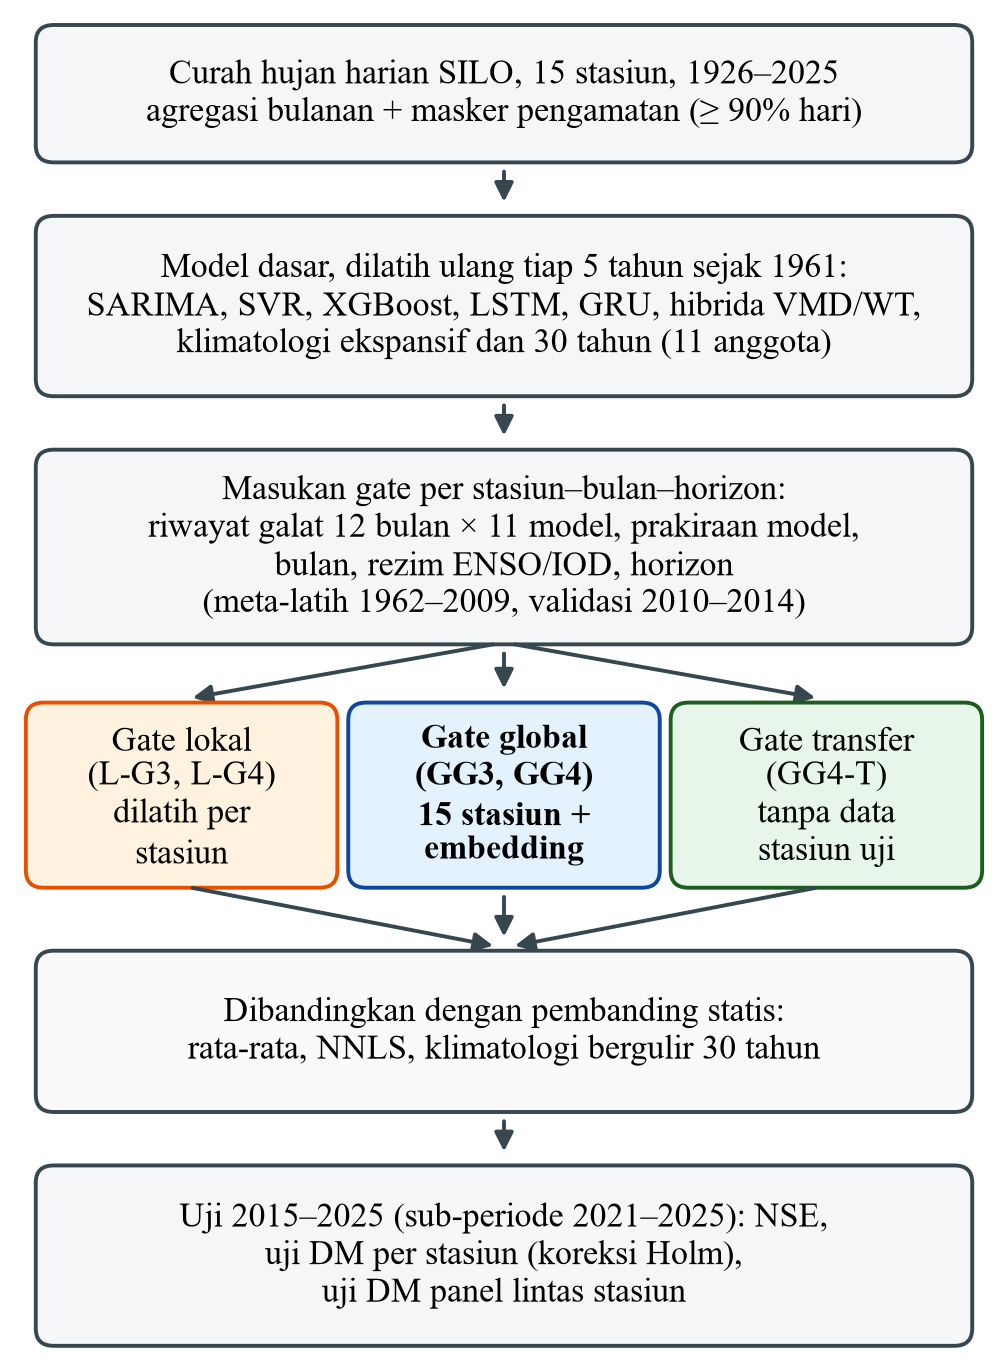

**Gambar 2. Skill MSE terhadap Klim30 per horizon pada dua sub-periode uji**

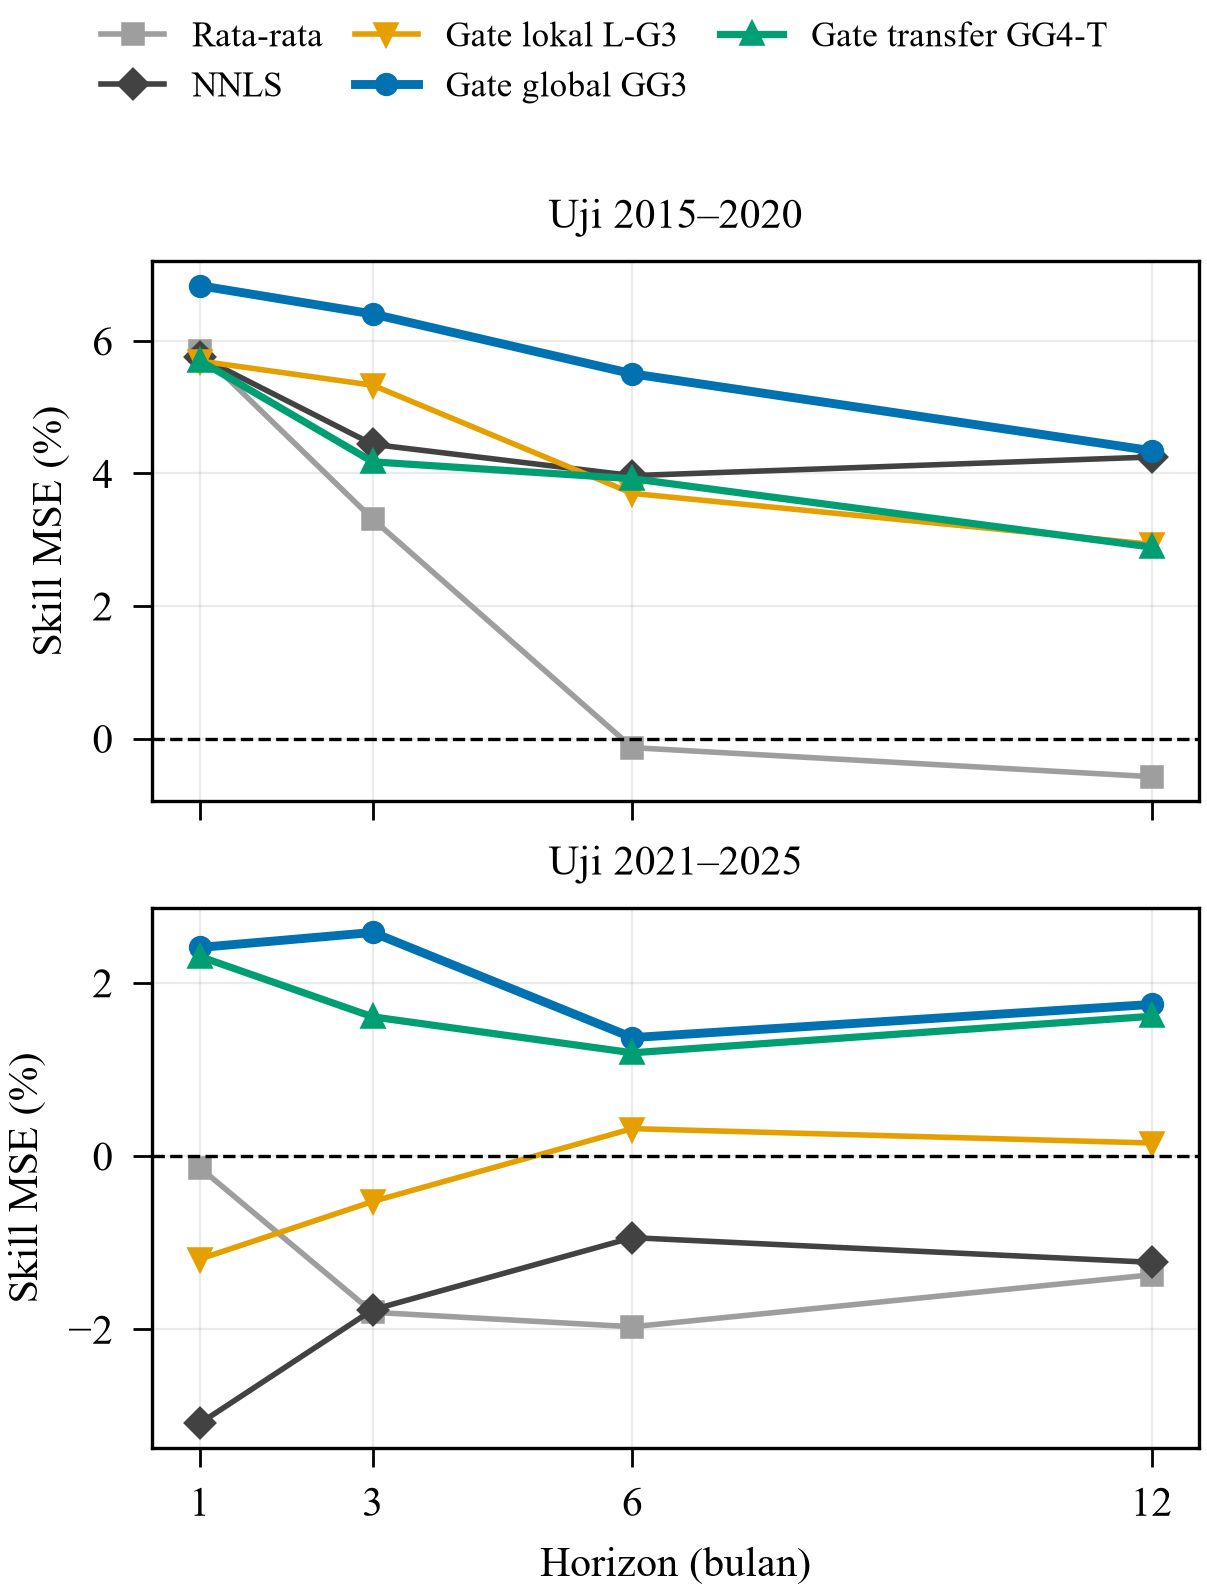

**Gambar 3. Penurunan MSE (%) GG3 per stasiun dan horizon: (a) terhadap L-G3, (b) terhadap NNLS; * = p < 0,05 sebelum koreksi Holm**

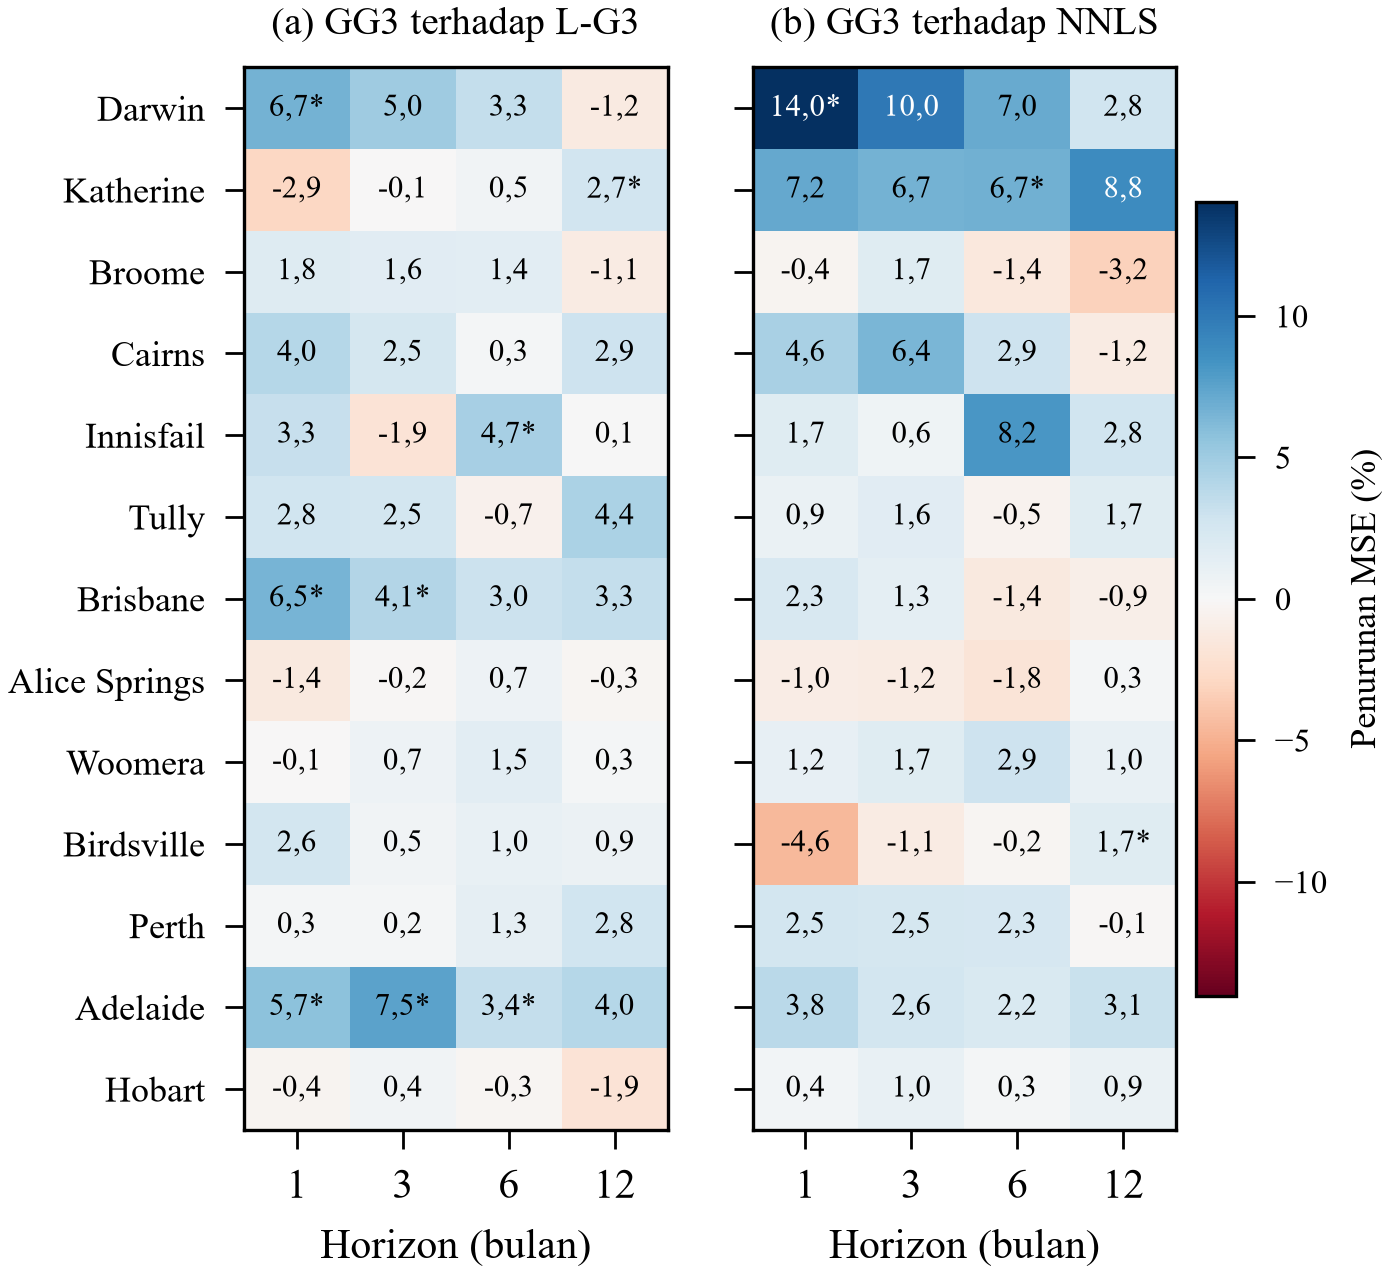

**Gambar 4. Bobot rata-rata GG3 per kelompok model menurut bulan target, Darwin dan Perth (h = 1)**

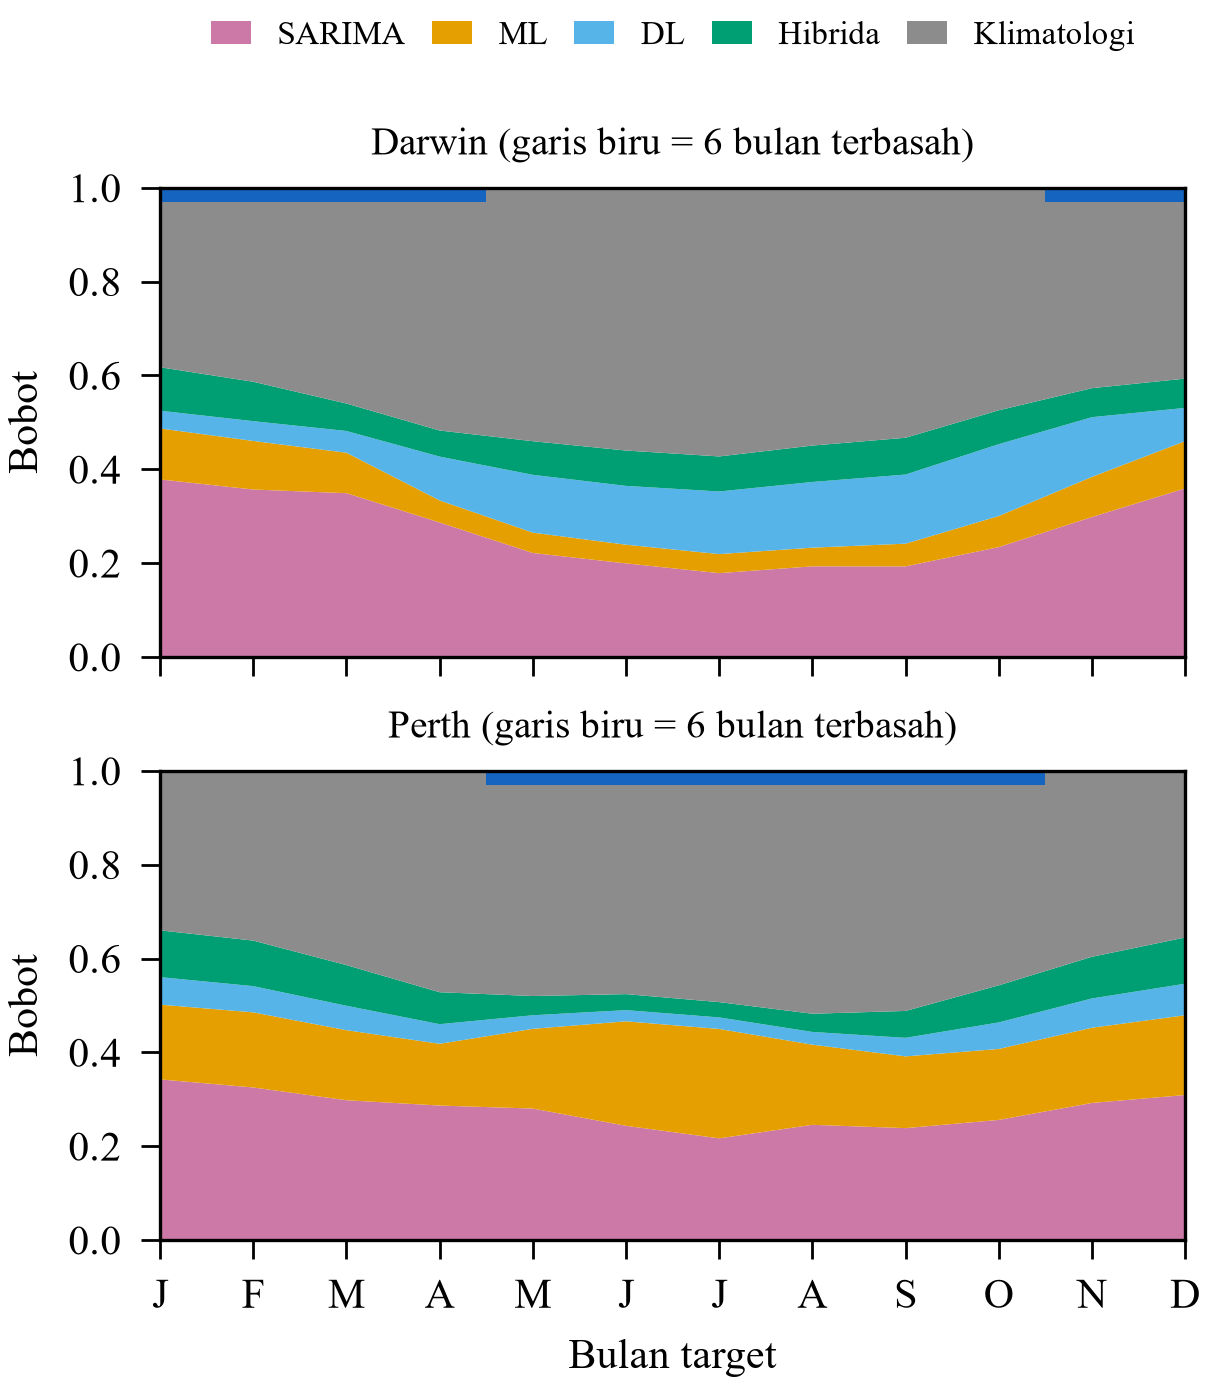

In [14]:
TG.semua_gambar()
cap = {"gambar1_kerangka.png": "Gambar 1. Kerangka penelitian",
       "gambar2_skill.png": "Gambar 2. Skill MSE terhadap Klim30 per horizon pada dua sub-periode uji",
       "gambar3_heatmap.png": "Gambar 3. Penurunan MSE (%) GG3 per stasiun dan horizon: (a) terhadap L-G3, (b) terhadap NNLS; * = p < 0,05 sebelum koreksi Holm",
       "gambar4_bobot.png": "Gambar 4. Bobot rata-rata GG3 per kelompok model menurut bulan target, Darwin dan Perth (h = 1)"}
for f, c in cap.items():
    display(Markdown(f"**{c}**")); display(Image(filename=str(ROOT / "laporan" / "naskah" / f), width=460))

## 8. Laporan eksperimen lengkap

Semua perbandingan berpasangan, DM panel untuk ketiga periode, menang/kalah per stasiun, diagnosis kelayakan ensemble, dan bobot gate. Hasilnya ditulis ke `laporan/eksperimen/` (CSV, `tabel_gate_global.xlsx`, dan gambar). Kode: `src/laporan_eksperimen.py`.

In [15]:
jalankan("laporan_eksperimen.py")


== nse_rerata
  Periode  h  n stasiun  Klimatologi 30 th  Klimatologi ekspansif  Rata-rata  NNLS  Model terbaik  Gate lokal G3  Gate lokal G4  Gate global GG3  Gate global GG4  Gate global transfer
2015-2025  1         13              0.300                  0.320      0.339 0.330          0.326          0.326          0.332            0.340            0.336                 0.338
2015-2025  3         13              0.300                  0.320      0.326 0.327          0.318          0.329          0.330            0.340            0.331                 0.332
2015-2025  6         13              0.300                  0.320      0.310 0.322          0.323          0.323          0.321            0.333            0.324                 0.329
2015-2025 12         13              0.300                  0.320      0.308 0.321          0.323          0.321          0.322            0.329            0.324                 0.324
2015-2020  1         13              0.259                  0.291

## 9. Pemeriksaan angka naskah

Sel ini membandingkan angka hasil evaluasi dengan angka yang dikutip di naskah. Pada mode reproduksi semua baris seharusnya bertanda ✓. Setelah pelatihan ulang, selisih kecil dapat muncul karena perbedaan perangkat keras atau versi pustaka.

In [16]:
R = json.load(open(HASIL / "hasil_evaluasi.json")); P = R["panel"]
def ph(c, per, h): return round(P[c][f"{per} h={h}"]["p_holm_horizon"], 3)
def nse(per, m): return [round(R["nse_rerata"][per][h][m], 3) for h in ["1", "3", "6", "12"]]
CEK = [
    ("NSE GG3 2015-2025 (h=1,3,6,12)", nse("2015-2025", "GG3"), [0.340, 0.340, 0.333, 0.329]),
    ("NSE GG4-T 2015-2025", nse("2015-2025", "GG4-transfer"), [0.338, 0.332, 0.329, 0.324]),
    ("NSE Klim30 2021-2025", nse("2021-2025", "Klim-30th"), [0.375, 0.375, 0.375, 0.375]),
    ("GG3 vs L-G3: p Holm panel h=1,3,6", [ph("GG3 vs L-G3", "2015-2025", h) for h in (1, 3, 6)], [0.008, 0.009, 0.033]),
    ("GG3 vs L-G3: menang dari 52", R["menang"]["GG3 vs L-G3"]["lebih baik"], 39),
    ("GG4 vs L-G4: p Holm panel h=1", ph("GG4 vs L-G4", "2015-2025", 1), 0.043),
    ("GG3 vs Klim30: p Holm panel h=1,3", [ph("GG3 vs Klim-30th", "2015-2025", h) for h in (1, 3)], [0.006, 0.006]),
    ("GG3 vs NNLS: p Holm panel h=3", ph("GG3 vs NNLS", "2015-2025", 3), 0.005),
    ("GG3 vs Rata2: p Holm panel h=6", ph("GG3 vs Rata-rata", "2015-2025", 6), 0.035),
    ("GG3 vs NNLS 2021-2025: p Holm h=1,3,6", [ph("GG3 vs NNLS", "2021-2025", h) for h in (1, 3, 6)], [0.017, 0.004, 0.0]),
    ("GG4-T vs Klim30: p Holm panel h=1", ph("GG4-transfer vs Klim-30th", "2015-2025", 1), 0.026),
    ("GG4-T vs GG4: p Holm minimum", min(ph("GG4-transfer vs GG4", "2015-2025", h) for h in (1, 3, 6, 12)), 0.633),
    ("Menang GG3 vs NNLS / Klim30 / Rata2", [R["menang"][c]["lebih baik"] for c in ["GG3 vs NNLS", "GG3 vs Klim-30th", "GG3 vs Rata-rata"]], [38, 43, 45]),
]
G = json.load(open(HASIL / "hasil_galat.json")); GP = G["panel"]
def pa(c, per, h): return round(GP[c][f"{per} h={h}"]["absolut"]["p_holm_horizon"], 3)
def gm(per, m, uk, d=2): return [round(G["rerata"][per][str(h)][m][uk], d) for h in (1, 3, 6, 12)]
CEK += [
    ("RMSE GG3 2015-2025 (mm)", gm("2015-2025", "GG3", "RMSE"), [87.13, 87.21, 87.52, 88.10]),
    ("MAE GG3 2015-2025 (mm)", gm("2015-2025", "GG3", "MAE"), [56.40, 56.59, 57.00, 57.41]),
    ("Skill MAE GG3 terhadap Klim30 2015-2025", gm("2015-2025", "GG3", "skill_MAE", 3), [0.020, 0.018, 0.010, 0.007]),
    ("Galat absolut, GG3 vs L-G3: p Holm h=1", pa("GG3 vs L-G3", "2015-2025", 1), 0.005),
    ("Galat absolut, GG3 vs NNLS: p Holm h=1,3", [pa("GG3 vs NNLS", "2015-2025", h) for h in (1, 3)], [0.003, 0.008]),
    ("Galat absolut, GG3 vs Klim30: p Holm minimum", min(pa("GG3 vs Klim-30th", "2015-2025", h) for h in (1, 3, 6, 12)), 0.156),
    ("Galat absolut 2021-2025, GG3 vs L-G3 / NNLS: p Holm h=1", [pa("GG3 vs L-G3", "2021-2025", 1), pa("GG3 vs NNLS", "2021-2025", 1)], [0.012, 0.018]),
    ("Menang MAE GG3 vs L-G3 / NNLS / Klim30 / Rata2",
     [G["menang_mae"][c]["2015-2025"]["menang"] for c in ["GG3 vs L-G3", "GG3 vs NNLS", "GG3 vs Klim-30th", "GG3 vs Rata-rata"]], [33, 33, 39, 47]),
]
for nama, nilai, naskah in CEK:
    ok = np.allclose(np.atleast_1d(nilai).astype(float), np.atleast_1d(naskah).astype(float), atol=5e-4)
    print("✓" if ok else "✗", f"{nama}: hasil = {nilai} | naskah = {naskah}")
display(Markdown("**Angka kunci per perbandingan**")); display(TG.angka_kunci())

✓ NSE GG3 2015-2025 (h=1,3,6,12): hasil = [0.34, 0.34, 0.333, 0.329] | naskah = [0.34, 0.34, 0.333, 0.329]
✓ NSE GG4-T 2015-2025: hasil = [0.338, 0.332, 0.329, 0.324] | naskah = [0.338, 0.332, 0.329, 0.324]
✓ NSE Klim30 2021-2025: hasil = [0.375, 0.375, 0.375, 0.375] | naskah = [0.375, 0.375, 0.375, 0.375]
✓ GG3 vs L-G3: p Holm panel h=1,3,6: hasil = [0.008, 0.009, 0.033] | naskah = [0.008, 0.009, 0.033]
✓ GG3 vs L-G3: menang dari 52: hasil = 39 | naskah = 39
✓ GG4 vs L-G4: p Holm panel h=1: hasil = 0.043 | naskah = 0.043
✓ GG3 vs Klim30: p Holm panel h=1,3: hasil = [0.006, 0.006] | naskah = [0.006, 0.006]
✓ GG3 vs NNLS: p Holm panel h=3: hasil = 0.005 | naskah = 0.005
✓ GG3 vs Rata2: p Holm panel h=6: hasil = 0.035 | naskah = 0.035
✓ GG3 vs NNLS 2021-2025: p Holm h=1,3,6: hasil = [0.017, 0.004, 0.0] | naskah = [0.017, 0.004, 0.0]
✓ GG4-T vs Klim30: p Holm panel h=1: hasil = 0.026 | naskah = 0.026
✓ GG4-T vs GG4: p Holm minimum: hasil = 0.633 | naskah = 0.633
✓ Menang GG3 vs NNLS / Kli

**Angka kunci per perbandingan**

,menang (dari 52),median penurunan MSE (%),"p Holm panel 2015-2025 (h=1,3,6,12)","p Holm panel 2021-2025 (h=1,3,6,12)"
GG3 vs L-G3,39,1.4,"[0.008, 0.009, 0.033, 0.169]","[0.032, 0.022, 0.42, 0.42]"
GG3 vs NNLS,38,1.7,"[0.135, 0.005, 0.243, 0.588]","[0.017, 0.004, 0.0, 0.074]"
GG3 vs Klim-30th,43,3.3,"[0.006, 0.006, 0.054, 0.086]","[0.775, 0.582, 0.846, 0.846]"
GG3 vs Rata-rata,45,1.9,"[0.44, 0.07, 0.035, 0.127]","[1.0, 0.549, 1.0, 1.0]"
GG4 vs L-G4,33,0.1,"[0.043, 0.324, 0.189, 0.088]","[0.046, 0.821, 0.662, 0.848]"
GG4-transfer vs GG4,28,0.1,"[0.633, 0.633, 0.633, 0.984]","[0.516, 0.516, 0.516, 0.516]"
GG4-transfer vs Klim-30th,38,2.2,"[0.026, 0.081, 0.092, 0.171]","[1.0, 1.0, 1.0, 1.0]"


## Catatan

- Perbandingan GG3 terhadap Rata2, NNLS, dan Klim30 ditambahkan setelah hasil awal terlihat, sehingga di naskah diperlakukan sebagai analisis eksploratori. RMSE, MAE, dan uji dengan galat absolut juga ditambahkan setelah hasil utama diperoleh.
- Model dasar dilatih dengan satu seed. Gate dilatih dengan tiga seed lalu dirata-rata.
- Coffs Harbour dan Melbourne hampir tidak memiliki bulan teramati pada 2015–2025, sehingga hanya dipakai untuk melatih gate global dan tidak dievaluasi.
- **Reproduksibilitas pelatihan ulang.** Keluaran yang tersimpan di `hasil/` direproduksi persis oleh mode reproduksi. Saat diuji di mesin lain dengan versi pustaka yang sama, dataset meta, gate lokal, dan gate transfer terulang sampai ketelitian float32 (selisih < 10⁻⁶), dan model dasar selain SARIMA juga terulang (SARIMA berselisih rata-rata ± 4% karena optimasi statsmodels bergantung pada platform). Gate global GG3 tidak terulang: pelatihan GG3 peka terhadap selisih numerik kecil antarmesin. Perubahan ini menggeser nilai *p* yang dekat batas 0,05. Pada uji tersebut, GG3 terhadap L-G3 tetap signifikan pada *h* = 1 dan 3 tetapi tidak lagi pada *h* = 6 (*p* Holm 0,057), dan keunggulan atas NNLS pada 2021–2025 tetap signifikan pada *h* = 1 dan 3 tetapi tidak pada *h* = 6. Menambah jumlah seed gate (variabel lingkungan `SEEDS`, misalnya `SEEDS=1,2,3,4,5,6,7,8,9,10`) akan mengurangi kepekaan ini.